### Carregar Bases

In [80]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

_img_size = (48,48)

def carregar_base_de_dados(caminho_principal, lista_classes, proporcao_teste):
    """
    Varre as subpastas no caminho_principal, processa as imagens e 
    retorna matrizes prontas para o treinamento da rede neural.
    """
    imagens_processadas = []
    labels_numéricos = []
    
    # Criamos um dicionário para mapear o nome da pasta para um número (ex: "Semibreve" -> 0)
    mapeamento_classes = {nome_classe: idx for idx, nome_classe in enumerate(lista_classes)}
    
    print("🔄 Iniciando o carregamento e processamento das imagens...")
    
    # 1. Percorre cada pasta de classe listada
    for nome_classe in lista_classes:
        caminho_pasta = os.path.join(caminho_principal, nome_classe)
        
        # Verifica se a pasta realmente existe para evitar erros
        if not os.path.isdir(caminho_pasta):
            print(f"⚠️ Aviso: A pasta '{nome_classe}' não foi encontrada em {caminho_principal}. Pulando...")
            continue
            
        codigo_classe = mapeamento_classes[nome_classe]
        
        # 2. Lista todos os arquivos dentro daquela subpasta
        for nome_arquivo in os.listdir(caminho_pasta):
            caminho_imagem = os.path.join(caminho_pasta, nome_arquivo)
            
            # Lê a imagem
            img = cv2.imread(caminho_imagem)
            if img is None:
                continue # Pula arquivos corrompidos ou que não sejam imagens
                
            # --- SEU PIPELINE DE TRATAMENTO DE IMAGEM ---
            # Converte para escala de cinza
            cinza = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            
            # Se a imagem não for 16x16, força o redimensionamento por segurança
            if cinza.shape != _img_size:
                cinza = cv2.resize(cinza, _img_size)
                
            # Pixels acima de 127 viram 255 (branco), abaixo viram 0 (preto)
            _, binaria = cv2.threshold(cinza, 127, 255, cv2.THRESH_BINARY)
            
            # Normaliza os valores para a escala entre 0.0 e 1.0
            X_normalizado = binaria / 255.0
            # ---------------------------------------------
            
            # Salva os dados processados nas listas
            imagens_processadas.append(X_normalizado)
            labels_numéricos.append(codigo_classe)
            
    # Converte as listas Python em arrays do NumPy eficientes
    X_dados = np.array(imagens_processadas)
    Y_dados = np.array(labels_numéricos)
    
    print(f"✅ Total carregado: {len(X_dados)} imagens.")
    
    # --- NOVA ETAPA: DIVISÃO EM TREINO E TESTE ---
    # random_state=42 garante que a divisão seja sempre a mesma ao rodar o script
    # stratify=Y_dados garante proporções iguais de classes no treino e teste
    X_train, X_test, Y_train, Y_test = train_test_split(
        X_dados, Y_dados, 
        test_size=proporcao_teste, 
        random_state=1, 
        stratify=Y_dados
    )
    
    print(f"📊 Divisão Concluída: Treino = {len(X_train)} | Teste = {len(X_test)}")
    return X_train, X_test, Y_train, Y_test

In [81]:
def embaralhar_dados(X, Y):
    """
    Embaralha as imagens e as respostas mantendo a correspondência correta.
    Cria uma lista de índices, Embaralha de forma aleatória e Retorna os dados reorganizados.
    """

    indices = np.arange(X.shape[0])
    np.random.shuffle(indices)
    
    return X[indices], Y[indices]

In [82]:
classes = ["Semibreve", "Minima", "Seminima", "Colcheia", "Semicolcheia"]#, "Fusa", "Semifusa"]
diretorio_base = r'C:\Users\jesse\SIN5016\dados_treino'

# Carrega e divide os dados (80% treino, 20% teste)
X_treino, X_teste, Y_treino, Y_teste = carregar_base_de_dados(diretorio_base, classes, proporcao_teste=0.2)

# Verificando os formatos gerados
print("\n--- Formatos Finais ---")
print("X_train (Treino):", X_treino.shape)
print("Y_train (Labels Treino):", Y_treino.shape)
print("X_test (Teste):", X_teste.shape)
print("Y_test (Labels Teste):", Y_teste.shape)

🔄 Iniciando o carregamento e processamento das imagens...
✅ Total carregado: 4250 imagens.
📊 Divisão Concluída: Treino = 3400 | Teste = 850

--- Formatos Finais ---
X_train (Treino): (3400, 48, 48)
Y_train (Labels Treino): (3400,)
X_test (Teste): (850, 48, 48)
Y_test (Labels Teste): (850,)


### Treino e Teste

In [83]:
# Hiperparametros
epocas = 20
taxa_de_aprendizado = 0.05
num_classes = len(classes)

# Configurações do Kernel
kernel = np.array([
    [-1,-1,-1],
    [-1,8,-1],
    [-1,-1,-1]
])
# Kernel de Suavização (Média) / Foco em Preenchimento e Textura (Cabeça da Nota)
# kernel = np.array([
#     [1/9, 1/9, 1/9],
#     [1/9, 1/9, 1/9],
#     [1/9, 1/9, 1/9]
# ])
# Sobel Vertical: Focado em capturar linhas verticais e diagonais (hastes e bandeirolas)
# kernel_hastes = np.array([
#         [-1,0,1], 
#         [-2,0,2], 
#         [-1,0,1]
# ])
k_conv = 3 # kernel.shape[0]

# Definindo o tamanho do Pooling para sabermos o tamanho da entrada densa
pool_size = 2
stride = 2
i_conv, j_conv = _img_size[0] - k_conv + 1, _img_size[1] - k_conv + 1
i_pool, j_pool = int((i_conv - pool_size) / stride + 1), int((j_conv - pool_size) / stride + 1)
tamanho_entrada_densa = i_pool * j_pool

# Pesos aleatórios pequenos
np.random.seed(1)
W = np.random.randn(num_classes, tamanho_entrada_densa) * 0.1
B = np.zeros((num_classes, 1))

In [84]:
for epoca in range(0, epocas):
    X_treino_shuffled, Y_treino_shuffled = embaralhar_dados(X_treino, Y_treino)

    perda_total = 0
    acertos = 0
    total_imagens = len(X_treino_shuffled)

    # Loop para processar cada imagem individualmente (Stochastic Gradient Descent)
    for i in range(total_imagens):
        X_individual = X_treino_shuffled[i]
        
        # 1. Monta o One-Hot Encoding para a imagem atual
        Y_real = np.zeros((num_classes, 1))
        Y_real[Y_treino_shuffled[i]] = 1.0

        # 2. FORWARD PROPAGATION

        # A) Convolução       
        mapa = np.zeros((i_conv, j_conv))
        for _i in range(i_conv):
            for _j in range(j_conv):                    
                fatia = X_individual[_i:_i+k_conv, _j:_j+k_conv]
                
                # Extração individual de cada filtro
                #carac_cabeca = (fatia * kernel).sum()
                #carac_hastes = (fatia * kernel_hastes).sum()

                # Combinação linear simples das características extraídas
                mapa[_i, _j] = (fatia * kernel).sum() # carac_cabeca + carac_hastes
                # mapa[_i, _j] = (X_individual[_i:_i+k_conv, _j:_j+k_conv] * kernel).sum()

        # B) ReLU
        mapa_caracteristicas = np.maximum(0, mapa)

        # C) Max Pooling
        mapa_pooling = np.zeros((i_pool, j_pool))
        for _i in range(i_pool):
            for _j in range(j_pool):
                r_start, c_start = _i * stride, _j * stride
                janela = mapa_caracteristicas[r_start:r_start+pool_size, c_start:c_start+pool_size]
                mapa_pooling[_i, _j] = np.max(janela)

        # D) Flatten e Camada Densa
        vetor_entrada = mapa_pooling.flatten().reshape(-1, 1)
        Z = np.dot(W, vetor_entrada) + B

        # E) Softmax
        exp_Z = np.exp(Z - np.max(Z))
        probabilidades = exp_Z / np.sum(exp_Z)

        # F) Acumula a Perda (Loss)
        perda_individual = -np.sum(Y_real * np.log(probabilidades + 1e-15))
        perda_total += perda_individual
        
        # G) Métrica de Acurácia (Verifica se o modelo acertou o palpite)
        if np.argmax(probabilidades) == Y_treino_shuffled[i]:
            acertos += 1

        # 3. BACKPROPAGATION
        dZ = probabilidades - Y_real
        dW = np.dot(dZ, vetor_entrada.T)
        dB = dZ

        # 4. ATUALIZAÇÃO DOS PESOS (Gradiente Descendente)
        W = W - taxa_de_aprendizado * dW
        B = B - taxa_de_aprendizado * dB
        
    # Média das métricas da época atual
    perda_media = perda_total / total_imagens
    acuracia = (acertos / total_imagens) * 100
    
    print(f"Época {epoca+1:02d}/{epocas} -> Perda Média: {perda_media:.4f} | Acurácia: {acuracia:.2f}%")


    # ---------------------------------------------------------
    # PARTE 2: PASSO DE TESTE (AVALIAÇÃO CEGA - SEM BACKWARD!)
    # ---------------------------------------------------------
    acertos_teste = 0
    perda_total_teste = 0
    
    # Passamos pelas 1000 imagens de teste usando o W e B que acabaram de ser atualizados
    for i in range(len(X_teste)):
        X_ind = X_teste[i]
        Y_real_teste = np.zeros((num_classes, 1))
        Y_real_teste[Y_teste[i]] = 1.0
        
        # 🔥 RECALCULANDO O FORWARD PARA A IMAGEM DE TESTE
        # A) Convolução teste
        mapa_teste = np.zeros((i_conv, j_conv))
        for _i in range(i_conv):
            for _j in range(j_conv):
                fatia_teste = X_ind[_i:_i+k_conv, _j:_j+k_conv]
                mapa_teste[_i, _j] = (fatia_teste * kernel).sum() # + (fatia_teste * kernel_hastes).sum()
                # mapa_teste[_i, _j] = (X_ind[_i:_i+k_conv, _j:_j+k_conv] * kernel).sum()

        # B) ReLU teste
        mapa_carac_teste = np.maximum(0, mapa_teste)

        # C) Max Pooling teste
        mapa_pool_teste = np.zeros((i_pool, j_pool))
        for _i in range(i_pool):
            for _j in range(j_pool):
                r_start, c_start = _i * stride, _j * stride
                janela_teste = mapa_carac_teste[r_start:r_start+pool_size, c_start:c_start+pool_size]
                mapa_pool_teste[_i, _j] = np.max(janela_teste)

        # D) Flatten e Camada Densa teste (Utiliza W e B que vieram do treino)
        vetor_entrada_teste = mapa_pool_teste.flatten().reshape(-1, 1)
        Z_teste = np.dot(W, vetor_entrada_teste) + B

        # E) Softmax teste
        exp_Z_teste = np.exp(Z_teste - np.max(Z_teste))
        probabilidades_teste = exp_Z_teste / np.sum(exp_Z_teste)
        
        # --- ACUMULA MÉTRICAS DE TESTE REAIS ---
        perda_total_teste += -np.sum(Y_real_teste * np.log(probabilidades_teste + 1e-15))
        if np.argmax(probabilidades_teste) == Y_teste[i]:
            acertos_teste += 1
            
    # Calcular as médias finais da época
    acc_teste = (acertos_teste / len(X_teste)) * 100
    
    print(f"Época {epoca+1:02d}/{epocas} -> Perda Média Teste: {perda_total_teste/len(X_teste):.4f} | Acurácia Teste: {acc_teste:.2f}%")
    print("-" * 60)

Época 01/20 -> Perda Média: 5.3329 | Acurácia: 60.21%
Época 01/20 -> Perda Média Teste: 7.4379 | Acurácia Teste: 60.12%
------------------------------------------------------------
Época 02/20 -> Perda Média: 4.3036 | Acurácia: 69.38%
Época 02/20 -> Perda Média Teste: 4.2252 | Acurácia Teste: 70.71%
------------------------------------------------------------
Época 03/20 -> Perda Média: 3.7886 | Acurácia: 72.29%
Época 03/20 -> Perda Média Teste: 4.3810 | Acurácia Teste: 69.65%
------------------------------------------------------------
Época 04/20 -> Perda Média: 3.4054 | Acurácia: 74.41%
Época 04/20 -> Perda Média Teste: 3.6786 | Acurácia Teste: 70.94%
------------------------------------------------------------
Época 05/20 -> Perda Média: 3.5234 | Acurácia: 74.53%
Época 05/20 -> Perda Média Teste: 4.0501 | Acurácia Teste: 73.53%
------------------------------------------------------------
Época 06/20 -> Perda Média: 3.1574 | Acurácia: 76.68%
Época 06/20 -> Perda Média Teste: 4.6200 

### Validação em lote

In [85]:
diretorio_validacao = r'C:\Users\jesse\SIN5016\dados_validacao'

# Carrega e divide os dados (80% treino, 20% teste)
X_valid_treino, X_valid_teste, Y_valid_treino, Y_valid_teste = carregar_base_de_dados(diretorio_validacao, classes, proporcao_teste=0.2)

X_valid = X_valid_treino
Y_valid = Y_valid_treino

🔄 Iniciando o carregamento e processamento das imagens...
✅ Total carregado: 750 imagens.
📊 Divisão Concluída: Treino = 600 | Teste = 150


### Predição

In [86]:
def omr(caminho_imagem, W, B, kernel, classes):
    # img = cv2.imread(caminho_imagem)
    # if img is None:
    #     return "Erro: Não foi possível carregar a imagem."
    
    # cinza = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # if cinza.shape != _img_size:
    #     cinza = cv2.resize(cinza, _img_size)

    # _, imagem_binaria = cv2.threshold(cinza, 127, 255, cv2.THRESH_BINARY)
    # X_nova = imagem_binaria / 255.0
    X_nova = caminho_imagem

    # 3. FORWARD PROPAGATION
    # A) Convolução
    mapa = np.zeros((i_conv, j_conv))
    for _i in range(i_conv):
        for _j in range(j_conv):
            fatia = X_nova[_i:_i+k_conv, _j:_j+k_conv]
            mapa[_i, _j] = (fatia * kernel).sum() # + (fatia * kernel_hastes).sum()

    # B) ReLU
    mapa_caracteristicas = np.maximum(0, mapa)

    # C) Max Pooling
    mapa_pooling = np.zeros((i_pool, j_pool))
    for _i in range(i_pool):
        for _j in range(j_pool):
            r_start, c_start = _i * stride, _j * stride
            janela = mapa_caracteristicas[r_start:r_start+pool_size, c_start:c_start+pool_size]
            mapa_pooling[_i, _j] = np.max(janela)

    # D) Flatten e Camada Densa (Usando W e B treinados)
    vetor_entrada = mapa_pooling.flatten().reshape(-1, 1)
    Z = np.dot(W, vetor_entrada) + B

    # E) Softmax
    exp_Z = np.exp(Z - np.max(Z))
    probabilidades = exp_Z / np.sum(exp_Z)

    # 4. Decisão da Rede
    indice_predito = np.argmax(probabilidades)
    classe_final = classes[indice_predito]
    confianca = probabilidades[indice_predito][0] * 100

    return indice_predito # f"🔮 O modelo identificou: {classe_final} ({confianca:.2f}% de certeza)"
    # return classe_final

In [87]:
valid = 0

for v in range(len(X_valid)):
    y_pred = omr(X_valid[v], W, B, kernel, classes)

    validated = Y_valid[v] == y_pred
    if (validated):
        valid+=1

acuracia_valid = (valid / len(X_valid)) * 100
print(f"Acertos: {valid} | Scoreatual: {acuracia_valid:.2f}% | Total de Avaliações: {len(X_valid)}")

Acertos: 445 | Scoreatual: 74.17% | Total de Avaliações: 600


In [88]:
# nova_imagem = r'C:\Users\jesse\SIN5016\bases\seminima_2.png'
# img_pred = omr(nova_imagem, W, B, kernel, classes)

# print(img_pred)

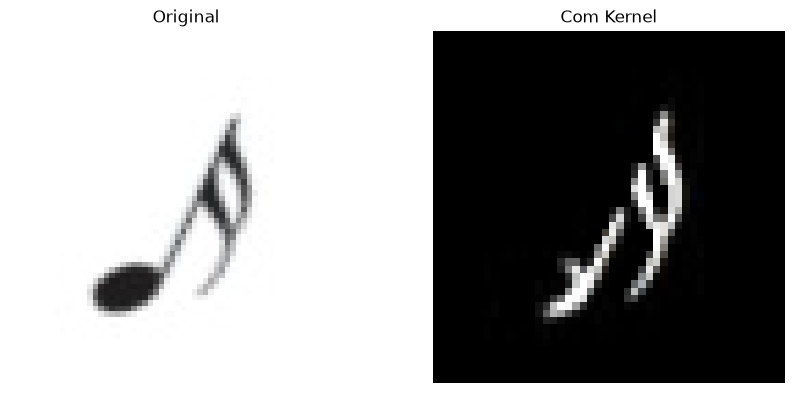

In [89]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Carregar a imagem
imagem = cv2.imread(r'C:\Users\jesse\SIN5016\dados_treino\Semicolcheia\s200.jpg')
imagem_rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

# 2. Definir o kernel (exemplo: kernel de nitidez / sharpen)
kernel = np.array([[-1,0,1], [-2,0,2], [-1,0,1]])

# 3. Aplicar a convolução usando o OpenCV
imagem_filtrada = cv2.filter2D(imagem_rgb, -1, kernel)
if imagem_filtrada.shape != (48,48):
    imagem_filtrada = cv2.resize(imagem_filtrada, (48,48))

# 4. Exibir o resultado lado a lado
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Original')
plt.imshow(imagem_rgb)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Com Kernel')
plt.imshow(imagem_filtrada)
plt.axis('off')
plt.show()
